## Table of Contents

- [1. Introduction](#1.-Introduction)
- [2. Imports and Configuration](#2.-Imports-and-Configuration)
- [3. Data Overview and Loading](#3.-Data-Overview-and-Loading)
  - [3.1. Sales Data](#3.1.-Sales-Data)
  - [3.2. Price Data](#3.2.-Price-Data)
  - [3.3. Calendar Data](#3.3.-Calendar-Data)
- [4. Time Series Analysis](#4.-Time-Series-Analysis)
  - [4.1. Time Series Plot](#4.1.-Time-Series-Plot)
  - [4.2. ACF and PACF of the Training Series](#4.2.-ACF-and-PACF-of-the-Training-Series)
  - [4.3. ACF and PACF After Seasonal Differencing](#4.3.-ACF-and-PACF-After-Seasonal-Differencing)
  - [4.4. Residual ACF and PACF of the Seasonal MA(1) Model](<#4.4.-Residual-ACF-and-PACF-of-the-Seasonal-MA(1)-Model>)
  - [4.5. Linear Trend Check in Model Residuals](#4.5.-Linear-Trend-Check-in-Model-Residuals)
- [5. Baseline Model Selection and Diagnostics](#5.-Baseline-Model-Selection-and-Diagnostics)
  - [5.1. Non-Seasonal AR and MA Order Comparison](#5.1.-Non-Seasonal-AR-and-MA-Order-Comparison)
  - [5.2. Model Selection and Diagnostics](#5.2.-Model-Selection-and-Diagnostics)
  - [5.3. Baseline Residual Diagnostics](#5.3.-Baseline-Residual-Diagnostics)
- [6. Feature Engineering](#6.-Feature-Engineering)
  - [6.1. Event Features](#6.1.-Event-Features)
  - [6.2 SNAP Features](#6.2-SNAP-Features)
    - [6.2.1 SNAP Calendar Patterns](#6.2.1-SNAP-Calendar-Patterns)
    - [6.2.2 SNAP Features](#6.2.2-SNAP-Features)
  - [6.3. Weekday Features](#6.3.-Weekday-Features)
  - [6.4. Month Features](#6.4.-Month-Features)
  - [6.5. Price Features](#6.5.-Price-Features)
  - [6.6. Combining Features and Sales](#6.6.-Combining-Features-and-Sales)
  - [6.7. Train and Final Validation Split](#6.7.-Train-and-Final-Validation-Split)
- [7. Exogenous Feature Ablation](#7.-Exogenous-Feature-Ablation)
  - [7.1 Selecting Feature Sets to Test](#7.1-Selecting-Feature-Sets-to-Test)
  - [7.2 Helper Functions](#7.2-Helper-Functions)
    - [7.2.1 Feature Transformation](#7.2.1-Feature-Transformation)
    - [7.2.2 Rank check helper function](#7.2.2-Rank-check-helper-function)
  - [7.3. Checking for Linearly Dependent Features](#7.3.-Checking-for-Linearly-Dependent-Features)
  - [7.4. Leave-One-Block-Out Feature Ablation](#7.4.-Leave-One-Block-Out-Feature-Ablation)
  - [7.5. Selecting Candidate Feature Sets](#7.5.-Selecting-Candidate-Feature-Sets)
  - [7.6. SARIMAX Validation of Candidate Feature Sets](#7.6.-SARIMAX-Validation-of-Candidate-Feature-Sets)
    - [7.6.1. Comparing Validation Results](#7.6.1.-Comparing-Validation-Results)
    - [7.6.2. Paired t-Test](#7.6.2.-Paired-t-Test)
- [8. Final Model Training and Evaluation](#8.-Final-Model-Training-and-Evaluation)
- [9. Conclusion](#9.-Conclusion)

## 1. Introduction

This project uses Walmart sales data from the [M5 Forecasting — Accuracy dataset](https://www.kaggle.com/c/m5-forecasting-accuracy/data) to develop a **28-day sales forecast using SARIMAX**. The dataset was released for a competition that required daily sales forecasts for the next 28 days, so we use the same 28-day forecast horizon.

We explore the data and test different features and model settings to improve forecast accuracy.

The dataset includes thousands of different products. Our analysis focuses on the product with item_id **FOODS_1_018**, selected because it provides a sales history covering the full study period. Daily unit sales are aggregated across the **four California stores** to form a single time series.

## 2. Imports and Configuration

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path
from matplotlib import pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import LinearRegression, Ridge
from statsmodels.tsa.stattools import adfuller, kpss
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import warnings
from scipy.stats import ttest_1samp


# Global variables

LOAD_TRAIN_RESULTS = True
forecast_horizon = 28

# The selected state is CA the product is FOODS_1_018
state = 'CA'

item_id = 'FOODS_1_018'


## 3. Data Overview and Loading

This project uses three source files from the [M5 Forecasting — Accuracy dataset](https://www.kaggle.com/c/m5-forecasting-accuracy/data). According to the dataset documentation, these files contain the following information:

| File | Contents |
|---|---|
| `sales_train_evaluation.csv` | Historical daily unit sales for each product and store, recorded in columns `d_1` to `d_1941`. The file also includes identifiers for the product, department, category, store, and state. |
| `sell_prices.csv` | Weekly average selling prices for each product and store, identified by `item_id`, `store_id`, and `wm_yr_wk`. |
| `calendar.csv` | Daily calendar information, including dates, day and week identifiers, weekdays, months, years, event names and types, and state-specific SNAP indicators. |

The files are loaded separately below. Their contents and relevance to the forecasting task are examined in the following sections.

### 3.1. Sales Data

In [7]:
sales_train_evaluation_path = Path('../Data/sales_train_evaluation.csv')
df_sales = pd.read_csv(sales_train_evaluation_path)
df_sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


### 3.2. Price Data

In [9]:
prices_path = Path('../Data/sell_prices.csv')
df_prices = pd.read_csv(prices_path)
df_prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


### 3.3. Calendar Data

In [11]:
calendar_path = Path('../Data/calendar.csv')
df_calendar = pd.read_csv(calendar_path)
df_calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [12]:
day_labels = [f'd_{i}' for i in range(1,1942)]
# df_sales_state = df_sales.groupby(by=['item_id','state_id'])[day_labels].sum()
# df_sales_state_day = df_sales_state[day_labels].T
# df_sales_state_day

## 4. Time Series Analysis

### 4.1. Time Series Plot

We sum the daily unit sales of **FOODS_1_018** across the **four California stores** to create a single time series.

We plot the series to look for trends, repeating patterns, and unusually high or low sales.

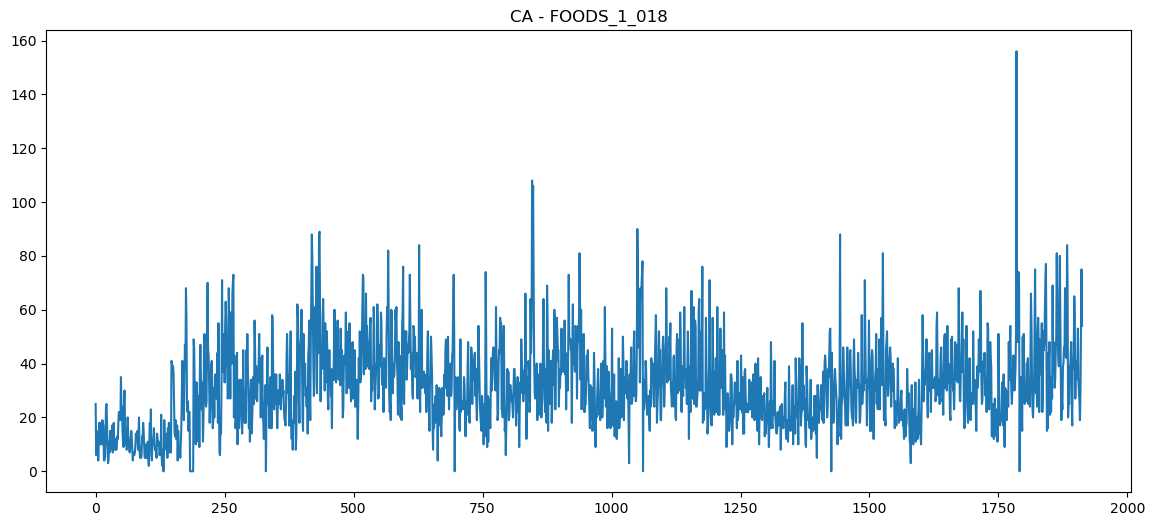

In [14]:
# We will build a predictive model to a product which has a continues data for all stores 
# Ploting the daily data

daily_data = df_sales[(df_sales['state_id'] == state) & (df_sales['item_id'] == item_id)][day_labels].T.sum(axis=1)
assert daily_data.isna().sum() == 0, 'NaN value in sales data'
plt.figure(figsize=(14,6))
plt.plot(range(len(daily_data[:-forecast_horizon])),daily_data[:-forecast_horizon])
plt.title(f'{state} - {item_id}')
plt.show()

Sales are lower at the start of the training period and then rise to a higher level. After this initial increase, there is no clear long-term trend. The series also shows several large spikes. No clear seasonal pattern is visible in this plot.

### 4.2. ACF and PACF of the Training Series

We set aside the last 28 days as the holdout set. We examine the autocorrelation function (ACF) and partial autocorrelation function (PACF) of the remaining training data to look for time dependence and seasonal patterns. These plots help us choose the SARIMAX model orders.

In [17]:
daily_data

d_1       25
d_2        6
d_3       15
d_4       11
d_5       11
          ..
d_1937    25
d_1938    48
d_1939    46
d_1940    63
d_1941    53
Length: 1941, dtype: int64

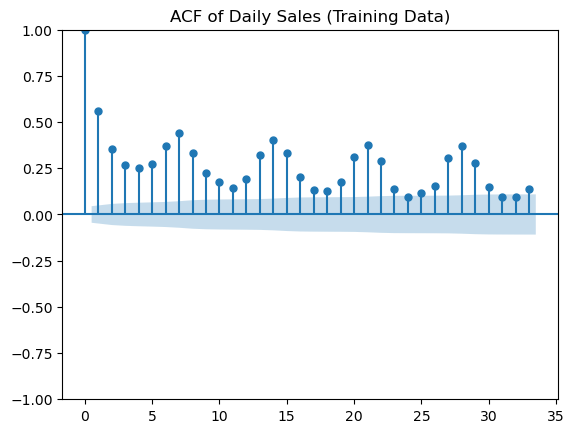

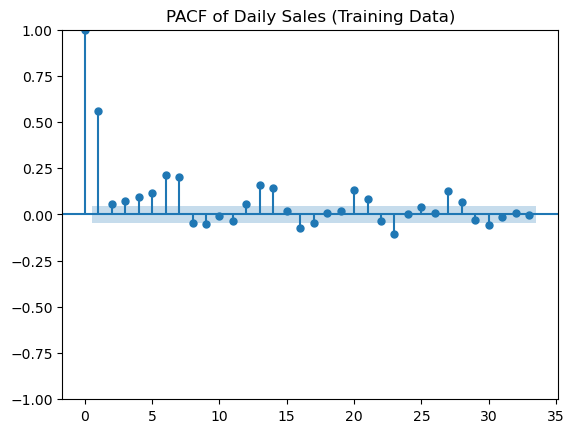

In [18]:
# Deciding the order of the model

df_training = daily_data.iloc[:-forecast_horizon]
df_validation = daily_data.iloc[-forecast_horizon:]

df_item_training = daily_data.iloc[:-forecast_horizon]
df_item_validation = daily_data.iloc[-forecast_horizon:]

plot_acf(
    df_item_training,
    title="ACF of Daily Sales (Training Data)"
)
plt.show()

plot_pacf(
    df_item_training,
    title="PACF of Daily Sales (Training Data)"
)
plt.show()

The ACF and PACF suggest a weekly seasonal pattern, with recurring spikes at lags 7, 14, 21, and 28. We therefore test a SARIMAX model with seasonal differencing at lag 7 and examine its residuals for remaining autocorrelation.

### 4.3. ACF and PACF After Seasonal Differencing

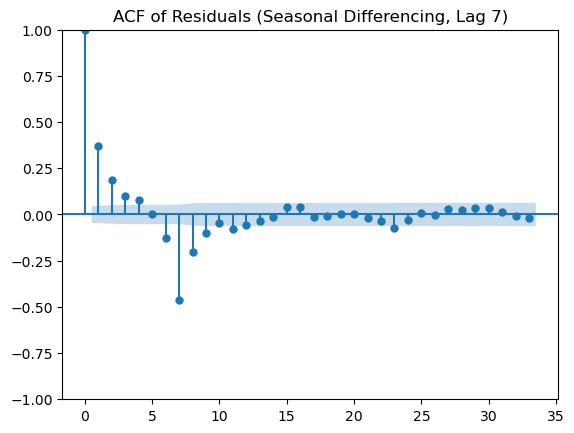

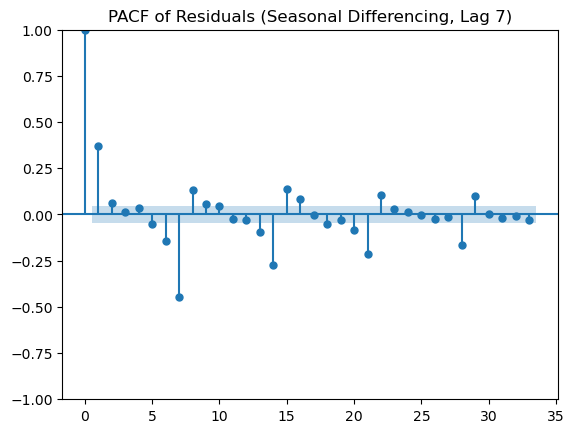

In [21]:
model_sarimax = SARIMAX(
    df_item_training.reset_index(drop=True),
    order=(0,0,0),
    seasonal_order=(0,1,0,7)
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    result = model_sarimax.fit(
        maxiter=1000 
    )

sesonality_removed = result.resid

plot_acf(
    sesonality_removed,
    title='ACF of Residuals (Seasonal Differencing, Lag 7)'
)
plt.show()

plot_pacf(
    sesonality_removed,
    title='PACF of Residuals (Seasonal Differencing, Lag 7)'
)
plt.show()

The ACF shows a negative spike at lag 7, while the PACF spikes at multiples of 7 gradually decrease in size. This suggests a seasonal MA(1) component. We therefore test `seasonal_order=(0,1,1,7)` and examine the residual ACF and PACF of the updated model.

### 4.4. Residual ACF and PACF of the Seasonal MA(1) Model

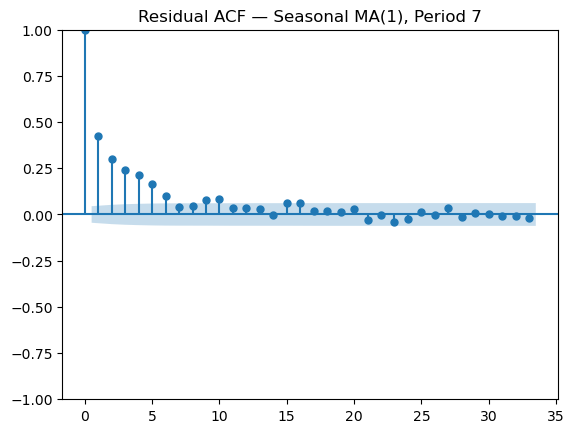

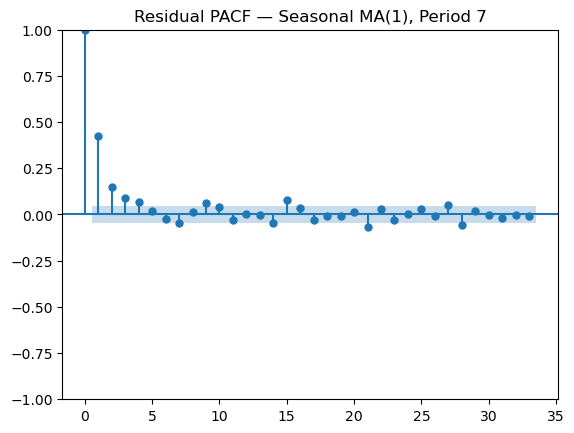

In [24]:
model_sarimax = SARIMAX(
    df_item_training.reset_index(drop=True),
    order=(0,0,0),
    seasonal_order=(0,1,1,7)
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    result = model_sarimax.fit(
        maxiter=1000 
    )
    
plot_acf(
    result.resid,
    title="Residual ACF — Seasonal MA(1), Period 7"
)
plt.show()

plot_pacf(
    result.resid,
    title="Residual PACF — Seasonal MA(1), Period 7"
)
plt.show()

The residual ACF of the model with a seasonal MA(1) component still shows positive autocorrelation at short lags. We therefore compare different non-seasonal AR and MA orders.

### 4.5. Linear Trend Check in Model Residuals

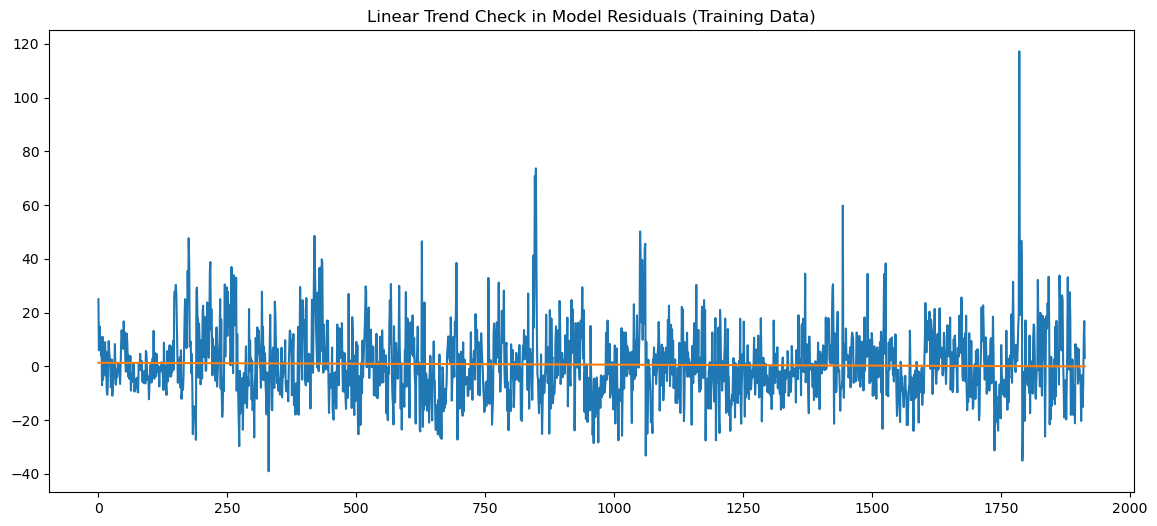

Residual trend slope: -0.00071090 units/day


In [27]:

# Ploting Residuals after removing 7 days sesonality

X = np.arange(len(result.resid)).reshape(-1,1)

model_lr = LinearRegression()

model_lr.fit(X,result.resid)

pred = model_lr.predict(X)

plt.figure(figsize=(14,6))
plt.plot(X,result.resid)
plt.plot(X,pred)
plt.title("Linear Trend Check in Model Residuals (Training Data)")
plt.show()
print(f"Residual trend slope: {model_lr.coef_[0]:.8f} units/day")

The fitted regression line is approximately flat, showing no clear linear trend in the residual. The residual ACF also decays towards zero. Based on this we start without non-seasonal differencing.

## 5. Baseline Model Selection and Diagnostics

### 5.1. Non-Seasonal AR and MA Order Comparison

#### Orders to Test

We keep `seasonal_order=(0, 1, 1, 7)` and test all 36 combinations of `order=(p, 0, q)`, with `p` and `q` ranging from 0 to 5.

#### Expanding-Window Validation

We use 13 consecutive 28-day validation periods within the training data, covering about one year. Since this is a time series, we train on all data before each validation period and predict the following 28 days. The training window grows as we move forward in time.

A model may perform well in one period and poorly in another. Testing several periods reduces the influence of one unusually good or bad result.

In [30]:
# Testing Ma and AR orders tzo miniminze the mse
# LOAD_TRAIN_RESULTS = True

null_model_seasonal_order = (0,1,1,7)

orders_to_test = [(ar,0,ma) for ar in range(0,6) for ma in range(0,6)]

df_order_test = pd.DataFrame(
    index=pd.MultiIndex.from_tuples(
        [],
        names=['order','step']
    )
)
df_order_test['converged'] = pd.Series(
    index=df_order_test.index,
    dtype='boolean'    
)

df_order_test_file = f'../Results/df_order_test_{item_id}_{state}.pkl'
df_order_test_path = Path(df_order_test_file)

if LOAD_TRAIN_RESULTS and df_order_test_path.exists():
    df_order_test = pd.read_pickle(df_order_test_path)


data_lenght = len(df_training)

for order in orders_to_test:

    for step in range(1,14):
    
        train_end = data_lenght - step * forecast_horizon

        X=df_item_training.iloc[:train_end]
        y=df_item_training.iloc[train_end:train_end + forecast_horizon]

        # print(f'{-step*forecast_horizon}:{-step*forecast_horizon+forecast_horizon}')

        if (order,step) not in df_order_test.index:
        
            model_sarimax = SARIMAX(
                X.reset_index(drop=True),
                order=order,
                seasonal_order=null_model_seasonal_order,
                trend='n'
            )
            # model_sarimax.initialize_approximate_diffuse()
            
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = model_sarimax.fit(
                    disp=False,
                    maxiter=1000 
                )
            
            forecast = result.get_forecast(steps=forecast_horizon).predicted_mean
                
            naiv_forecast = list(df_item_training.iloc[train_end - 7 :train_end])
            naiv_forecast.extend(naiv_forecast)
            naiv_forecast.extend(naiv_forecast)
            
            naiv_mse = mean_squared_error(naiv_forecast,y)
            mse = mean_squared_error(forecast,y)
            
            df_order_test.at[(order,step),'naiv_scaled_mse'] = mse / naiv_mse
            df_order_test.at[(order,step),'mse'] = mse
            df_order_test.at[(order,step),'converged'] = result.mle_retvals["converged"]
            # df_order_test.at[(order,step),'aic'] = result.aic
            # df_order_test.at[(order,step),'bic'] = result.bic
            # df_order_test.at[(order,step),'aicc'] = result.aicc
            print(f"Evaluated order {order} | Fold {step}/13".ljust(80), end="\r", flush=True)
            
        else:
            print(f"Loading result | Order {order} | Fold {step}/13".ljust(80), end="\r", flush=True)

# df_order_test['mse_rank'] = df_order_test['mse'].groupby(by="step").rank()

df_order_test.to_pickle(df_order_test_path)
print(f'ARMA order testing completed. Results saved to: {df_order_test_path}')

print(f'Number of non-converged fits: {(df_order_test["converged"] == False).sum()}')

# LOAD_TRAIN_RESULTS = False

df_order_test

ARMA order testing completed. Results saved to: ..\Results\df_order_test_FOODS_1_018_CA.pkl
Number of non-converged fits: 0


converged  naiv_scaled_mse         mse
order     step                                        
(0, 0, 0) 1          True         0.200878  119.522511
          2          True         0.623985  303.212179
          3          True         0.798136  206.004581
          4          True         0.527276  140.406078
          5          True         0.932156  947.603598
...                   ...              ...         ...
(5, 0, 5) 9          True         0.686729  100.654796
          10         True         0.498593   57.943616
          11         True         0.646837  170.187341
          12         True         0.550316   92.570959
          13         True         0.916528  163.633070

[468 rows x 3 columns]

All 36 models converged on all 13 validation folds, so all candidate models were included in the MSE comparison.

### 5.2. Model Selection and Diagnostics

#### Scoring and Model Selection

1. **Why we scale the MSE.** Forecast errors can differ greatly between validation periods. We compare each model with the same benchmark within each fold to measure its relative performance across periods.

2. **Seasonal naive benchmark.** This forecast assumes that the weekly sales pattern repeats. In each fold, we repeat the last seven training days four times to predict the next 28 days.

3. **Scaled MSE.** We divide the model’s MSE by the benchmark’s MSE on the same validation period. A ratio below 1 means the model performed better than the benchmark; a ratio above 1 means it performed worse.

4. **Model selection.** We average these ratios across the 13 folds, giving each fold’s relative score equal weight. We select the model with the lowest average as our null model.

#### Diagnostics

We refit the top five candidates on the full training data and check whether they converge. We also report their BIC and examine their residuals:

- **ADF and KPSS** help assess residual stationarity.
- **Ljung–Box** checks for remaining autocorrelation up to lags 7, 14, 21, and 28.

These results provide additional information about the models. Selection remains based on the mean scaled validation MSE.

In [33]:
df_order_stats = pd.DataFrame()

df_order_stats['naiv_scaled_mse'] = df_order_test['naiv_scaled_mse'].groupby(by='order').mean()

df_order_stats[
    ['bic', 'kpss', 'adf', 'lb7', 'lb14', 'lb21', 'lb28']
] = np.nan

df_order_stats['full_fit_converged'] = pd.Series(
    pd.NA,
    index=df_order_stats.index,
    dtype='boolean'
)

df_order_stats = df_order_stats.sort_values('naiv_scaled_mse')

for order in df_order_stats.index[:5]:

    print(f"Evaluated order {order}".ljust(80), end="\r", flush=True)
    model_sarimax = SARIMAX(
        df_item_training.reset_index(drop=True),
        order=order,
        seasonal_order=null_model_seasonal_order,
        trend='n'
    )

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        result = model_sarimax.fit(
            disp=False,
            maxiter=1000 
        )

    converged = result.mle_retvals.get('converged', False)
    df_order_stats.at[order, 'full_fit_converged'] = converged

    if not converged: continue
        
    df_order_stats.at[order,'bic'] = result.bic

    burn = max(result.loglikelihood_burn, result.nobs_diffuse)
    resid = result.filter_results.standardized_forecasts_error[0, burn:]

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        df_order_stats.at[order, 'adf'] = adfuller(
            resid, regression='c', autolag='AIC'
        )[1]
    
        df_order_stats.at[order, 'kpss'] = kpss(
            resid, regression='c', nlags='auto'
        )[1]

    lb_result = result.test_serial_correlation(
        method='ljungbox',
        lags=[7,14,21,28],
        df_adjust=True
    )

    df_order_stats.at[order, 'lb7'] = lb_result[0, 1, 0]
    df_order_stats.at[order, 'lb14'] = lb_result[0, 1, 1]
    df_order_stats.at[order, 'lb21'] = lb_result[0, 1, 2]
    df_order_stats.at[order, 'lb28'] = lb_result[0, 1, 3]

null_model_order = df_order_stats.index[0]

print('Residual diagnostics completed for the top 5 candidates.'.ljust(80))
print(f'Best model by mean scaled validation MSE: {null_model_order} score: {df_order_stats["naiv_scaled_mse"].iloc[0]:.6f}).')

df_order_stats.head()

Residual diagnostics completed for the top 5 candidates.                        
Best model by mean scaled validation MSE: (1, 0, 2) score: 0.553052).


,naiv_scaled_mse,bic,kpss,adf,lb7,lb14,lb21,lb28,full_fit_converged
order,,,,,,,,,
"(1, 0, 2)",0.553052,14720.902354,0.044221,0.0,0.095695,0.043565,0.019743,0.001445,True
"(1, 0, 3)",0.557788,14720.440518,0.100000,0.0,0.102771,0.009468,0.014536,0.001423,True
"(2, 0, 1)",0.558935,14712.985881,0.100000,0.0,0.105097,0.013111,0.017186,0.001546,True
"(3, 0, 5)",0.566891,14742.258643,0.100000,0.0,NaN,0.002331,0.005493,0.001845,True
"(1, 0, 4)",0.567085,14725.026803,0.100000,0.0,0.020173,0.010782,0.012347,0.001183,True


#### Model Selection Results

- **Selected model.** We select (1, 0, 2) as our null model without exogenous variables because it has the lowest mean scaled validation MSE (0.553052), using the seasonal naive forecast as the benchmark.

- **BIC comparison.** BIC evaluates model fit with a penalty for additional parameters. Lower values are preferred. Our selected model has the third-lowest BIC among the five best models by validation score.

- **Residual diagnostics.** The Ljung–Box test checks for remaining residual autocorrelation. For all five models, including the selected model, the tests up to lags 14, 21, and 28 have p-values below 0.05, suggesting that some autocorrelation remains. KPSS also rejects level stationarity for the selected model at the 5% level (`p=0.044`). Missing exogenous effects could be one possible explanation, but the test does not identify the cause.

### 5.3. Baseline Residual Diagnostics

We examine the residual ACF and PACF to check whether the selected null model has captured the main time patterns in sales. Remaining autocorrelation may indicate patterns that the model has not captured.

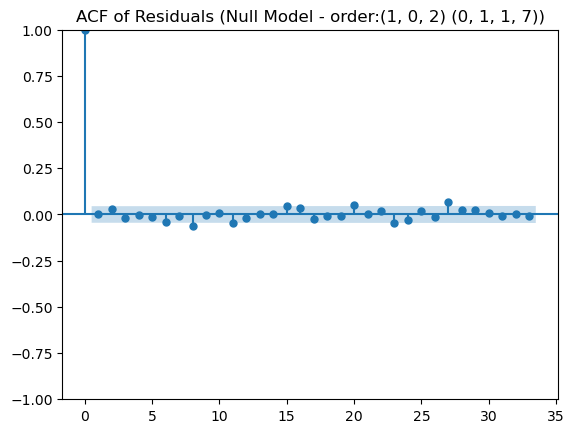

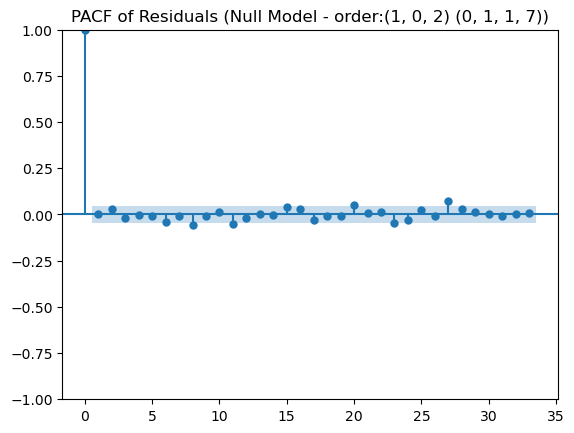

In [36]:
model_sarimax = SARIMAX(
    df_item_training.reset_index(drop=True),
    order=null_model_order,
    seasonal_order=null_model_seasonal_order
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    result = model_sarimax.fit(
        maxiter=1000 
    )


warmup_period = max(result.loglikelihood_burn, result.nobs_diffuse)

resid = result.filter_results.standardized_forecasts_error[0, warmup_period:]

plot_acf(
    resid,
    title=f'ACF of Residuals (Null Model - order:{null_model_order} {null_model_seasonal_order})'
)
plt.show()

plot_pacf(
    resid,
    title=f'PACF of Residuals (Null Model - order:{null_model_order} {null_model_seasonal_order})'
)
plt.show()

Most residual correlations fall within the 95% confidence bands, and the ACF and PACF show no clear seasonal pattern. A few spikes extend beyond the bands.

## 6. Feature Engineering

We use the available data to build exogenous features for the sales forecast. These include calendar events, SNAP schedules, and month indicators. We then test whether adding these features improves 28-day forecasts compared with the baseline model.

### 6.1. Event Features

For each event name and event type, we create three features:

- **Event-day indicator** marks the day of the event. Sales on that day may differ from sales in the days around it.
- **Before-event feature (`__before`)** uses the number of days until the event within the preceding 14 days. Sales may rise before Christmas, for example, if shoppers make larger purchases in preparation for the holiday.
- **After-event feature (`__after`)** uses the number of days since the event within the following 14 days. Sales may fall after Christmas if shoppers have already stocked up.

We model the periods before and after each event separately because sales can move in different directions. We also include squared terms for both features so the model can capture changes that speed up or slow down over time.

In [40]:
# Helper function for adding higher order features

def add_higher_order_features(df,indicator=['__before','__after','__rel_chg'],order=2):

    df = df.copy()

    for feature in [feature for feature in df if any(feature.endswith(txt) for txt in indicator)]:
        
        for ord in range(2,order+1):
                        
            df[f'{feature}__ord{ord}'] = df[feature]**ord
        
        df = df.copy()

    return df

In [41]:
# Event days list with week id, events might have a pre effect since people might change their purchasing behaiver before the event,
# this effect could start even fweeks before the event, it might also change on the actual day of the event, 
# so a separate feature might be needed for the event day itself and the preceeding days which are getting closer to the event
# the additional feature will be measuring how many days are to the actual events in the preceeding 14 days and will increase 1 in every day
# The event actual name includes is type as well as an information

df_events = df_calendar.set_index('d')[['wm_yr_wk','event_name_1','event_type_1','event_name_2','event_type_2']].copy()
event_names = set(df_events['event_name_1'].dropna()).union(df_events['event_name_2'].dropna())

for event in sorted(event_names):
    df_events[event] = ((df_events['event_name_1'] == event) | (df_events['event_name_2'] == event)).astype(int)

    df_events[f'{event}__before'] = df_events[event].shift(-1,fill_value=0)
    df_events[f'{event}__after'] = df_events[event].shift(1,fill_value=0)
    
    for i in range(2,15):
        df_events[f'{event}__before'] = df_events[f'{event}__before'] + df_events[event].shift(-i,fill_value=0) * i
        df_events[f'{event}__after'] = df_events[f'{event}__after'] + df_events[event].shift(i,fill_value=0) * i

df_events = df_events.copy()

event_type_names = set(df_events['event_type_1'].dropna()).union(df_events['event_type_2'].dropna())

for event_type in sorted(event_type_names):
    df_events[event_type] = ((df_events['event_type_1'] == event_type) | (df_events['event_type_2'] == event_type)).astype(int)

    df_events[f'{event_type}__before'] = df_events[event_type].shift(-1,fill_value=0)
    df_events[f'{event_type}__after'] = df_events[event_type].shift(1,fill_value=0)

    for i in range(2, 15):
        # In case of event types two events can follow each other witin the 14 days, 
        # so the closer events day is considered in the after and before feature
        event_type_ahead = df_events[event_type].shift(-i, fill_value=0).eq(1)
        event_type_behind = df_events[event_type].shift(i, fill_value=0).eq(1)

        df_events.loc[event_type_ahead & df_events[f'{event_type}__before'].eq(0), f'{event_type}__before'] = i
        df_events.loc[event_type_behind & df_events[f'{event_type}__after'].eq(0), f'{event_type}__after'] = i


df_events = df_events.drop(columns=['event_name_1', 'event_type_1',	'event_name_2',	'event_type_2'])
df_events = add_higher_order_features(df_events)

event_feature_names = df_events.drop(columns='wm_yr_wk').columns

df_events

,wm_yr_wk,Chanukah End,Chanukah End__before,Chanukah End__after,Christmas,Christmas__before,Christmas__after,Cinco De Mayo,Cinco De Mayo__before,Cinco De Mayo__after,...,VeteransDay__before__ord2,VeteransDay__after__ord2,Cultural__before__ord2,Cultural__after__ord2,National__before__ord2,National__after__ord2,Religious__before__ord2,Religious__after__ord2,Sporting__before__ord2,Sporting__after__ord2
d,,,,,,,,,,,,,,,,,,,,,
d_1,11101,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,64,0
d_2,11101,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,49,0
d_3,11101,0,0,0,0,0,0,0,0,0,...,0,0,196,0,0,0,0,0,36,0
d_4,11101,0,0,0,0,0,0,0,0,0,...,0,0,169,0,0,0,0,0,25,0
d_5,11101,0,0,0,0,0,0,0,0,0,...,0,0,144,0,0,0,0,0,16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
d_1965,11620,0,0,0,0,0,0,0,0,0,...,0,0,16,0,0,0,0,64,16,169
d_1966,11620,0,0,0,0,0,0,0,0,0,...,0,0,9,0,0,0,0,81,9,196
d_1967,11620,0,0,0,0,0,0,0,0,0,...,0,0,4,0,0,0,0,100,4,0


### 6.2 SNAP Features
#### 6.2.1 SNAP Calendar Patterns

We examine the California SNAP indicator to see how long each active period lasts and how often it starts. This helps us decide whether to include day counters alongside the binary indicator.

In [43]:
# Snap payment, after snap payment the purchase might change so an additional snap after feature is added which indicats the days passed between snaps and the last snap day
df_snap = df_calendar.set_index('d')[f'snap_{state}'].to_frame()
df_snap.columns=[f'snap_{state}']

df_snap['snap_run'] = df_snap[f'snap_{state}'].groupby(df_snap[f'snap_{state}'].eq(0).cumsum()).cumsum()
df_snap['no_snap_run'] = (1 - df_snap[f'snap_{state}']).groupby(df_snap[f'snap_{state}'].eq(1).cumsum()).cumsum()

df_snap['idx'] = df_snap.index.str.split('_').str[1].astype(int)

df_snap_start = df_snap[df_snap['snap_run'] == 1]['idx']

snap_lenght = df_snap[f'snap_run'][df_snap['snap_run'] != 0].groupby(df_snap[f'snap_{state}'].eq(0).cumsum()).max().unique()
print(f'Snap period leghts: {snap_lenght}')

days_between_snaps = (df_snap_start - df_snap_start.shift(1)).dropna().unique()
print(f'Days between snap starts: {days_between_snaps}')

idx = df_snap[
    (df_snap['snap_CA'] == 1) &
    (df_snap['snap_CA'].shift(1) == 0)
].index

snap_start_days = df_calendar.reset_index().set_index('d').loc[
                                                idx,
                                                'date'
                                            ].str.split('-').str[2].unique()

print(f'Calendar Days when Span payment starts: {snap_start_days}')

# df_snap = df_snap.drop(columns=['snap_run','no_snap_run','idx']).copy()

# no_snap_lenght = df_snap[f'no_snap_run'][df_snap['no_snap_run'] != 0].groupby(df_snap[f'snap_{state}'].eq(1).cumsum()).max().unique()
# print(f'Days between Snaps: {no_snap_lenght}')



Snap period leghts: [10]
Days between snap starts: [28. 31. 30. 29.]
Calendar Days when Span payment starts: ['01']


In the M5 calendar, California’s SNAP indicator is active from the 1st through the 10th of each month. We use this pattern to create two features: the day within the active period and the number of days since it ended.

#### 6.2.2 SNAP Features

- **`snap_CA`** marks days in the active SNAP period and lets the model capture an overall difference in sales between active and inactive days.
- **`snap_CA__before`** counts the days until the next active period within the preceding week. Sales may fall if some shoppers delay larger purchases until their benefits become available.
- **`snap_run`** tracks the day within the active period. Benefits become available to different households on different days, and some households may shop a day or two later. Sales may therefore build over the first few days of the period.
- **`snap_CA__after`** counts the days since the active period ended. Sales may remain elevated for a while and gradually return to their usual level.

We include squared terms for all three counters so the model can capture nonlinear sales patterns before, during, and after the active SNAP period.

In [46]:
df_snap['swap'] = df_snap['snap_CA'] != df_snap['snap_CA'].shift(1)
df_snap['group'] = df_snap['swap'].cumsum()
df_snap['lenght_count'] = df_snap['swap'].groupby(by=df_snap['group']).cumcount() + 1
df_snap['snap_CA__after'] = df_snap['lenght_count'].where(df_snap['snap_CA'] == 0,0)
# Correcting the first 3 snap after value
df_snap.loc[['d_1','d_2','d_3'],'snap_CA__after'] = [19, 20, 21]

df_snap['idx'] = df_snap.index.to_series().str.split('_').str[1].astype(int)

df_snap['next_snap_idx'] = df_snap['idx'].where(
    df_snap['swap'] & df_snap['snap_CA'].eq(1)
).bfill()

df_snap['days_before'] = df_snap['next_snap_idx'] - df_snap['idx']

df_snap['snap_CA__before'] = df_snap['days_before'].where(
    df_snap['snap_CA'].eq(0) & df_snap['days_before'].between(1, 7),
    0
).astype(int)

df_snap = add_higher_order_features(
    df_snap[['snap_CA','snap_run','snap_CA__after','snap_CA__before']].copy(),
    indicator=['_run','__before','__after']
)
snap_feature_names = list(df_snap.columns)

df_snap

,snap_CA,snap_run,snap_CA__after,snap_CA__before,snap_run__ord2,snap_CA__after__ord2,snap_CA__before__ord2
d,,,,,,,
d_1,0,0,19,3,0,361,9
d_2,0,0,20,2,0,400,4
d_3,0,0,21,1,0,441,1
d_4,1,1,0,0,1,0,0
d_5,1,2,0,0,4,0,0
...,...,...,...,...,...,...,...
d_1965,0,0,5,0,0,25,0
d_1966,0,0,6,0,0,36,0
d_1967,0,0,7,0,0,49,0


### 6.3. Weekday Features

One-hot weekday indicators repeat every seven days. The model uses seven-day seasonal differencing, which subtracts each indicator’s value from its value on the same weekday one week earlier. The resulting indicators are all zero, so we omit weekday features from the model.

### 6.4. Month Features

We use one-hot indicators to capture recurring differences in sales across calendar months. We create indicators for January through November and use December as the reference month, represented by zeros in all 11 columns.

In [49]:
# Creating month indicator with one hot encoding month_12 will be the default month
df_month_indicator = df_calendar.set_index('d')['month'].to_frame()
df_month_indicator.columns=['month']

for i in range(1,12):
    df_month_indicator[f'month__{i}'] = (df_month_indicator['month'] == i).astype(int)

df_month_indicator = df_month_indicator.drop(columns='month')
month_feature_names = list(df_month_indicator.columns)

df_month_indicator

,month__1,month__2,month__3,month__4,month__5,month__6,month__7,month__8,month__9,month__10,month__11
d,,,,,,,,,,,
d_1,1,0,0,0,0,0,0,0,0,0,0
d_2,1,0,0,0,0,0,0,0,0,0,0
d_3,1,0,0,0,0,0,0,0,0,0,0
d_4,0,1,0,0,0,0,0,0,0,0,0
d_5,0,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
d_1965,0,0,0,0,0,1,0,0,0,0,0
d_1966,0,0,0,0,0,1,0,0,0,0,0
d_1967,0,0,0,0,0,1,0,0,0,0,0


### 6.5. Price Features

We examine price features, to see how often the price changes in each store.

In [51]:
#Sell price

df_price_features = df_prices[df_prices['store_id'].str.contains(state) & (df_prices['item_id'] == item_id)].set_index('wm_yr_wk')

df_price_features = df_price_features.drop(columns='item_id').pivot(
        columns=['store_id'],
        values=['sell_price']
    )

df_price_features.columns = [f'{name[0]}__{name[1]}' for name in df_price_features]

for col in df_price_features:
    price_change_count = (df_price_features[col] != df_price_features[col].shift(1,fill_value=df_price_features[col].iloc[0])).sum()
    print(f'Number of price changes in store {col}: {price_change_count}')



Number of price changes in store sell_price__CA_1: 1
Number of price changes in store sell_price__CA_2: 1
Number of price changes in store sell_price__CA_3: 1
Number of price changes in store sell_price__CA_4: 1


Prices changed only once in each store over the observed period. This limited variation makes it difficult to assess the relationship between price and sales, so we exclude price features from the forecasting models.

### 6.6. Combining Features and Sales

We align the event, SNAP, and month features with daily sales using the M5 day identifier. We check that each day appears only once and that the retained data contain no missing values. We then separate the sales target from the exogenous features.

In [54]:
# puting all features together
df_all_features = df_sales[(df_sales['item_id'] == item_id) & (df_sales['state_id'] == state)][day_labels].sum().to_frame()

df_all_features.columns = [item_id]


df_all_features = pd.concat(
    [
        df_all_features,
        df_events,
        df_snap,
        # df_week_days,
        df_month_indicator
    ],
    axis=1
)

assert len(df_all_features.index) == len(df_all_features.index.unique()), 'df_all_features indexes are not unique'

idx_nan = df_all_features[df_all_features.isna().any(axis=1)].index

df_all_features = df_all_features.drop(index=idx_nan)

#checking continuity
idx = df_all_features.index
idx = [int(i.split('_')[1]) for i in idx]
idx = pd.Series(idx)
none_continues_index = ((idx-idx.shift(1,fill_value=idx[0]-1)) != 1).sum()

assert none_continues_index == 0 , 'Index are not continues'

df_all_features = df_all_features.drop(columns='wm_yr_wk')

assert df_all_features.isna().sum().sum() == 0, 'NaN valu remained in df_all_features'

df_item = df_all_features[item_id]

df_all_features = df_all_features.drop(columns=item_id)
df_all_features

,Chanukah End,Chanukah End__before,Chanukah End__after,Christmas,Christmas__before,Christmas__after,Cinco De Mayo,Cinco De Mayo__before,Cinco De Mayo__after,ColumbusDay,...,month__2,month__3,month__4,month__5,month__6,month__7,month__8,month__9,month__10,month__11
d_1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
d_2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
d_3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
d_4,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
d_5,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
d_1937,0,0,0,0,0,0,0,0,13,0,...,0,0,0,1,0,0,0,0,0,0
d_1938,0,0,0,0,0,0,0,0,14,0,...,0,0,0,1,0,0,0,0,0,0
d_1939,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
d_1940,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


### 6.7. Train and Final Validation Split

We split the data into a training set and a holdout set. We use the holdout set for the final evaluation.

In [56]:
df_training = df_all_features.iloc[:-forecast_horizon]
df_item_training = df_item.iloc[:-forecast_horizon]

df_validation = df_all_features.iloc[-forecast_horizon:]
df_item_validation = df_item.iloc[-forecast_horizon:]
df_training
# df_validation

,Chanukah End,Chanukah End__before,Chanukah End__after,Christmas,Christmas__before,Christmas__after,Cinco De Mayo,Cinco De Mayo__before,Cinco De Mayo__after,ColumbusDay,...,month__2,month__3,month__4,month__5,month__6,month__7,month__8,month__9,month__10,month__11
d_1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
d_2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
d_3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
d_4,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
d_5,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
d_1909,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
d_1910,0,0,0,0,0,0,0,14,0,0,...,0,0,1,0,0,0,0,0,0,0
d_1911,0,0,0,0,0,0,0,13,0,0,...,0,0,1,0,0,0,0,0,0,0
d_1912,0,0,0,0,0,0,0,12,0,0,...,0,0,1,0,0,0,0,0,0,0


## 7. Exogenous Feature Ablation

We check whether the available features can explain part of the residuals of our SARIMA null model. We apply the same SARIMA filter to sales and the candidate features, then use Ridge regression to check whether removing a feature block increases validation MSE.

We use these results to build candidate feature sets and fit a SARIMAX model with each set. We then compare the 28-day forecast MSE of these models with that of the SARIMA baseline on the original sales scale.

### 7.1 Selecting Feature Sets to Test

We create two feature sets. One uses event types, and the other uses event names. Both include the same SNAP and month features. Event names describe the same calendar events in more detail than event types. Since the two representations overlap, we test them separately.

In [58]:
# Feature sets
feature_sets = {
    'event_type': 
        # price_feature_names +
        month_feature_names + 
        # week_day_feature_names + 
        snap_feature_names +
        [col for col in event_feature_names if any([event_type in col for event_type in event_type_names])],
    'event_names':
        # price_feature_names +
        month_feature_names + 
        # week_day_feature_names + 
        snap_feature_names +
        [col for col in event_feature_names if any([event_name in col for event_name in event_names])]    
}

# print(feature_sets['event_names'])
# feature_sets


### 7.2 Helper Functions

#### 7.2.1 Feature Transformation

To test whether the exogenous features can help predict sales, we apply the same SARIMA filter from the null model to both the sales series and the features.

In [60]:
# Helper function to transformig the features with the null model sarimax order=(0,0,0) sesional_order=(0,1,1,7)

def transform_features(X,order,seasonal_order,params):
    _, diff, _ = order
    _,sesional_diff,_,s_order  = seasonal_order
    
    ar_coef = [ar for ar in params.index if ar.startswith('ar.L')]
    ma_coef = [ma for ma in params.index if ma.startswith('ma.L')]

    ar_s_coef = [ar for ar in params.index if ar.startswith('ar.S.L')]
    ma_s_coef = [ma for ma in params.index if ma.startswith('ma.S.L')]
    
    
    # print(ar_coef)
    # print(ma_coef)

    # print(ar_s_coef)
    # print(ma_s_coef)  

    X_transf = X.copy()
    
    for i in range(diff):
        X_transf = X_transf - X_transf.shift(1)
        
    for i in range(sesional_diff):
        X_transf = X_transf - X_transf.shift(s_order)

    # print(params[ar_coef])

    X_ar = X_transf.copy()
    
    for ar in ar_coef:
        lag = int(ar.split('L')[-1])
        X_transf = X_transf - params[ar] * X_ar.shift(lag)

    for s_ar in ar_s_coef:
        s_lag = int(s_ar.split('L')[-1])
        X_transf = X_transf - params[s_ar] * X_ar.shift(s_lag)
        
        for ar in ar_coef:
            lag = int(ar.split('L')[-1])
            X_transf = X_transf + params[ar] * params[s_ar] * X_ar.shift(s_lag + lag)

    X_transf = X_transf.dropna().copy()
    
    for i in range(1,len(X_transf)):
        
        for ma in ma_coef:
            lag = int(ma.split('L')[-1])
            if i >= lag:
                X_transf.iloc[i] = X_transf.iloc[i] - params[ma] * X_transf.iloc[i-lag]

    for i in range(1,len(X_transf)):
        
        for s_ma in ma_s_coef:
            s_lag = int(s_ma.split('L')[-1])

            if i >= s_lag:
                X_transf.iloc[i] = X_transf.iloc[i] - params[s_ma] * X_transf.iloc[i - s_lag]
                
                    
    
    return X_transf

# transform_features(df_training,null_model_order,(0,1,1,7),result.params)

#### 7.2.2 Rank check helper function

Helper function to remove linearly dependent features using a matrix rank check.

In [62]:

def rank_check(X_rank_scr):

    scaler = StandardScaler()
    
    # X_rank_scr = df_training.iloc[:-forecast_horizon].drop(columns=item_id)
    
    X_rank_scaled = pd.DataFrame(
        scaler.fit_transform(X_rank_scr),
        index=X_rank_scr.index,
        columns=X_rank_scr.columns
    )
    
    all_feature_labels = X_rank_scr.columns
    
    features_to_keep = []
    features_to_remove = []
    rank = 0
    
    for feature in all_feature_labels:
        
        X_np = X_rank_scaled[features_to_keep + [feature]].to_numpy()
        new_rank = np.linalg.matrix_rank(X_np)
        
        if new_rank > rank:
            rank = new_rank
            features_to_keep.append(feature)
        else:
            features_to_remove.append(feature)

    print(f'Dropped features count:{len(features_to_remove)}')
    print('Droped Fetaures:\n')
    for feature in features_to_remove:
        print(feature)
        
    print(f'Remaining features count: {len(features_to_keep)}\n-------------------\n')
    
    return features_to_keep, features_to_remove

### 7.3. Checking for Linearly Dependent Features

We transform both feature sets and use the rank check to remove any linearly dependent features.

In [64]:
# Calculating null model parameters for transformation
model_sarimax = SARIMAX(
    df_item_training.reset_index(drop=True),
    order=null_model_order,
    seasonal_order=null_model_seasonal_order,
    trend='n'
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    result = model_sarimax.fit(
        disp=False,
        maxiter=1000 
    )
result.summary()

#Coefficient for the feature transformation
params = result.params
# print(f'Parameters of MA Sesional 7:\n{params}')


# Checking lineary dependant features
for f_set in feature_sets:
    print(f'Feature set: {f_set}\n')

    df_to_rank_check = df_training[feature_sets[f_set]]
    df_to_rank_trans = transform_features(df_to_rank_check,null_model_order,null_model_seasonal_order,params)
    
    feature_sets[f_set] = rank_check(df_to_rank_trans)[0]

# feature_sets

Feature set: event_type

Dropped features count:0
Droped Fetaures:

Remaining features count: 38
-------------------

Feature set: event_names

Dropped features count:0
Droped Fetaures:

Remaining features count: 168
-------------------



### 7.4. Leave-One-Block-Out Feature Ablation

#### Basic Idea

Some features may help the model make better predictions, while others may add noise or offer little extra information. We start with a model that uses all candidate features. We then leave out one feature at a time, retrain the model, and compare its validation MSE with that of the full model. If the MSE increases after removing a feature, that feature helped the model on the validation window.

We use these comparisons to decide which features to keep.

#### Implementation

1. **Arranging the features into blocks.** Some features are closely related, such as the before and after features for each event. We put these related features in the same block and evaluate them together.
2. **Fit the full model.** We fit a Ridge model with all features included in the current feature set and use it as the reference for the comparison.
3. **Remove one feature block at a time.** We refit the model with one block removed and compare its MSE with the full model’s MSE on the same validation window. We calculate both errors on the SARIMA-filtered sales series.

#### Validation Windows

We use different validation windows because the features follow different patterns. SNAP periods occur every month, while some events occur only once a year and can affect sales mainly around the event date.

- **SNAP and month features.** We use 13 validation windows of 28 days with an expanding training window. Together, the validation windows cover about one year.
- **Event names and event types.** Event features are active around event dates, so we check their effect during these periods. We train on the data before each event window and validate on the event day and up to 14 days before and after it. This covers the period represented by the feature block. We require at least one year of training data to cover a full annual cycle. For annual events with five occurrences in the data, using at least one occurrence for training leaves at most four validation folds.

In [66]:
# helper function for training models and calculating mse with the selected features and with the null model

# LOAD_TRAIN_RESULTS = True

def calculate_mse(features_to_test,train_end,val_end,order,seasonal_order):

    model_sarimax = SARIMAX(
        df_item.iloc[:train_end].reset_index(drop=True),
        order=order,
        seasonal_order=seasonal_order,
        trend='n'
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        result = model_sarimax.fit(
            maxiter=1000 ,
            disp=False
        )
    params =result.params
    
    X_trans = transform_features(
            df_training.iloc[:val_end][features_to_test],
            order,
            seasonal_order,
            params
    )

    
    srinkage = val_end - len(X_trans)

    y_trans = transform_features(
            df_item.iloc[:val_end],
            order,
            seasonal_order,
            params
    )


    X_train = scaler.fit_transform(
        X_trans.iloc[:train_end - srinkage]
        
    )
    
    X_val = scaler.transform(
        X_trans.iloc[train_end - srinkage:val_end - srinkage],
                )

    y_train = y_trans.iloc[:train_end - srinkage]
        
    
    y_val = y_trans.iloc[train_end - srinkage:val_end - srinkage]

    assert X_trans.index.equals(y_trans.index), "Different X és y indexes"    
    
    model_lr = Ridge(max_iter=5000)
    model_lr.fit(X_train,y_train)

    # assert model_lr.rank_ == X_train.shape[1], 'Rank check failed X_train including linearry dependent features'

    pred_val = model_lr.predict(X_val)

    mse_val = mean_squared_error(pred_val,y_val)
    
    return mse_val

df_lr_results_file = f'../Results/df_lr_results_{item_id}_{state}.pkl'
df_lr_results_path = Path(df_lr_results_file)


if LOAD_TRAIN_RESULTS and df_lr_results_path.exists():
    df_lr_results = pd.read_pickle(df_lr_results_path)

else:
    
    df_lr_results = pd.DataFrame(
        # columns=['pred_val'],
        index=pd.MultiIndex.from_tuples(
            [],
            names=['feature_set','excluded_block','fold']
        )
    )

scaler = StandardScaler()


not_event_features = month_feature_names + snap_feature_names

count_between_saves = 0
save_intervall = 0

for f_set in feature_sets:
    #Selecting the feature block using the '__' separation in the feature names
    blocks_to_exclude = list(
        dict.fromkeys(
            [s.split('__',1)[0] for s in feature_sets[f_set] if s in not_event_features]
        )
    )
    # Training not event features
    for block in blocks_to_exclude:
    
        features_to_test = []
        
        for feature in feature_sets[f_set]:
            if block != feature.split('__', 1)[0]:
                features_to_test.append(feature)
        
        for train_set_end in range(
            len(df_training) - 13 * forecast_horizon,
            len(df_training),
            forecast_horizon
        ):
            
            # Only run the training if it missing from the DataFrame
            if (f_set,block,train_set_end) not in df_lr_results.index:
           
                # Training with one feature left out
                df_lr_results.loc[(f_set,block,train_set_end),'mse_val'] = calculate_mse(
                    features_to_test,
                    train_set_end,
                    train_set_end + forecast_horizon,
                    null_model_order,
                    null_model_seasonal_order
                )
                # Training full model with all features
                df_lr_results.loc[(f_set,block,train_set_end),'mse_full'] = calculate_mse(
                    feature_sets[f_set],
                    train_set_end,
                    train_set_end + forecast_horizon,
                    null_model_order,
                    null_model_seasonal_order
                )
                
                print(f'Training started - Feature set:{f_set} - Feature Block excluded:{block} Validation index start:{train_set_end}'.ljust(100),end='\r', flush=True)
                count_between_saves += 1
                if count_between_saves >= save_intervall:
                    count_between_saves = 0
                    df_lr_results.to_pickle(df_lr_results_path)
                    print(f'Results saved to: {df_lr_results_file}'.ljust(100),end='\r', flush=True)
            else:
                print(f'{(f_set,block,train_set_end)} Loaded from {df_lr_results_path}'.ljust(100),end='\r', flush=True)
                        

    # Training event features
    event_features = sorted(set(feature_sets[f_set]) - set(not_event_features))
    
    for event in [
        event for event in event_features 
        if not any(indicator in event for indicator in ['__before','__after'])]:

        features_to_test = []
        for feature in feature_sets[f_set]:
            if event != feature.split('__', 1)[0]:
                features_to_test.append(feature)

        idx_list = np.flatnonzero(df_training[event] == 1)
        
        start_idx_list = [max(idx,0) for idx in idx_list - 14]
        end_idx_list = [min(idx,len(df_training)) for idx in idx_list + 15]
      
        for start_idx,end_idx in zip(start_idx_list[1:],end_idx_list[1:]):

            # Minimum one year training data is needed, only run the training if it missing from the DataFrame
            if start_idx > 365 and (f_set,event,start_idx) not in df_lr_results.index:
                
                print(f'Training started - Feature set:{f_set} - Event left out:{event} Validation index range:{start_idx}:{end_idx}',end='\r', flush=True)  
                df_lr_results.loc[(f_set,event,start_idx),'mse_val'] = calculate_mse(
                    features_to_test,
                    start_idx,
                    end_idx,
                    null_model_order,
                    null_model_seasonal_order
                )
                # Training full model with all features
                df_lr_results.loc[(f_set,event,start_idx),'mse_full'] = calculate_mse(
                    feature_sets[f_set],
                    start_idx,
                    end_idx,
                    null_model_order,
                    null_model_seasonal_order
                )
                
                count_between_saves += 1
                if count_between_saves >= save_intervall:
                    count_between_saves = 0
                    df_lr_results.to_pickle(df_lr_results_path)
                    print(f'Results saved to: {df_lr_results_path}'.ljust(100),end='\r', flush=True)
            else:
                print(f'{(f_set,event,start_idx)} Loaded from {df_lr_results_path}'.ljust(100),end='\r', flush=True)

df_lr_results.to_pickle(df_lr_results_path)
print(f'Results saved to: {df_lr_results_path}'.ljust(100),end='\r', flush=True)        

df_lr_results

Results saved to: ..\Results\df_lr_results_FOODS_1_018_CA.pkl                                       

mse_val    mse_full
feature_set excluded_block fold                        
event_type  month          1549   61.578293   75.104278
                           1577   71.513180   74.870416
                           1605   66.183963   65.646286
                           1633   85.210122   85.696811
                           1661   98.126712   98.115182
...                                     ...         ...
event_names ValentinesDay  1828  276.778544  248.834612
            VeteransDay    638    93.448794   88.272082
                           1003   89.529383  100.086483
                           1368   84.682614   85.494905
                           1733   90.347799   85.328676

[332 rows x 2 columns]

### 7.5. Selecting Candidate Feature Sets


#### Basic Idea

We use the ablation results to decide which feature blocks to keep. In each fold, we divide the MSE after removing a block by the MSE of the model with all features and subtract 1. This helps us compare the effect of removing a block across folds with different levels of forecast error.

For feature block $g$ and fold $f$, we calculate the relative MSE change and then average it across the $n_g$ folds used to evaluate that feature set.

$$
\Delta_{g,f}
= \frac{\mathrm{MSE}_{-g,f}}{\mathrm{MSE}_{\mathrm{full},f}} - 1,
\qquad
\overline{\Delta}_g
= \frac{1}{n_g}\sum_{f=1}^{n_g}\Delta_{g,f}.
$$

#### Implementation

We apply two selection steps to each original feature set.

1. **Select blocks by mean relative MSE change.** We keep blocks with $\overline{\Delta}_g > 0$. Removing these blocks increased validation MSE on average. The retained blocks form the first candidate.
2. **Apply a hit rate filter.** A hit is a fold in which removing the block increased MSE. The hit rate is the proportion of folds with a hit. A single large increase can outweigh several decreases in the average, so we form a stricter candidate by keeping only blocks from the first candidate with a hit rate of at least 75%.

In Section 7.6, we evaluate each nonempty candidate using SARIMAX on the original sales series and compare it with the SARIMA baseline without exogenous features.

In [68]:
# Selecting features to test with the sarimax model. Selection criteria is a mse improvement with a secondary 75% hit rate screaning

df_lr_results['hit'] = (df_lr_results['mse_val'] > df_lr_results['mse_full']).astype(int)
df_lr_results['inverse_hit'] = (df_lr_results['mse_val'] <= df_lr_results['mse_full']).astype(int)
df_lr_results['mse_improvement'] = (df_lr_results['mse_val'] / df_lr_results['mse_full']) - 1


df_hit_stat = pd.DataFrame()

df_hit_stat['hit_count'] = df_lr_results.groupby(by=['feature_set','excluded_block']).sum()['hit']
df_hit_stat['inverse_hit_count'] = df_lr_results.groupby(by=['feature_set','excluded_block']).sum()['inverse_hit']
df_hit_stat['hit_rate'] = df_hit_stat['hit_count'] / (df_hit_stat['hit_count'] + df_hit_stat['inverse_hit_count'])
df_hit_stat['mean_mse_improvement'] = df_lr_results['mse_improvement'].groupby(by=['feature_set','excluded_block']).mean()

hit_rate_treshold = 0.75
mse_impr_treshold = 0.0
sarimax_features_to_test = {}

for f_set in feature_sets:
    
    df_f_set = df_hit_stat.xs(
        f_set,
        level='feature_set'
    )

    hit_rate_feature_list = list(
        df_f_set[
            (df_f_set['hit_rate'] >= hit_rate_treshold) &
            (df_f_set['mean_mse_improvement'] > mse_impr_treshold)
        ].index
    )
    
    mse_impr_feature_list = list(
        df_f_set[
            df_f_set['mean_mse_improvement'] > mse_impr_treshold
        ].index
    )
    
    if hit_rate_feature_list:
        sarimax_features_to_test[f'{f_set}__hit_rate'] = hit_rate_feature_list
    if mse_impr_feature_list:
        sarimax_features_to_test[f'{f_set}__mse_impr'] = mse_impr_feature_list
    
sarimax_features_to_test['null_model'] = []
sarimax_features_to_test


print(f'\n{"=" * 60}')
print('CANDIDATE FEATURE SETS')
print(f'{"=" * 60}')

for group_name, features in sarimax_features_to_test.items():
    print(f'\n{group_name} ({len(features)} feature blocks)')
    print('-' * 60)

    if features:
        for i, feature in enumerate(features, 1):
            print(f'  {i:>2}. {feature}')
    else:
        print('  No features selected.')

print(f'\n{"=" * 60}')

            
# df_hit_stat.sort_values(by=['feature_set','mse_improvement'],ascending=False)


CANDIDATE FEATURE SETS

event_type__mse_impr (2 feature blocks)
------------------------------------------------------------
   1. month
   2. snap_run

event_names__hit_rate (3 feature blocks)
------------------------------------------------------------
   1. Christmas
   2. Easter
   3. Thanksgiving

event_names__mse_impr (7 feature blocks)
------------------------------------------------------------
   1. Christmas
   2. Easter
   3. LentStart
   4. Thanksgiving
   5. VeteransDay
   6. snap_CA
   7. snap_run

null_model (0 feature blocks)
------------------------------------------------------------
  No features selected.



### 7.6. SARIMAX Validation of Candidate Feature Sets

We fit a SARIMAX model for each candidate feature set and compare it with the null model a SARIMA model without exogenous features. We use 13 expanding-window folds with 28-day validation periods, covering about one year to compare performance across different seasons and events. We keep the model orders fixed and calculate the validation MSE on the original sales series.

In [70]:
# Sarimax test

# LOAD_TRAIN_RESULTS = False

df_sarimax_results_file = f'../Results/df_sarimax_results_{item_id}_{state}.pkl'
df_sarimax_results_path = Path(df_sarimax_results_file)

if LOAD_TRAIN_RESULTS and df_sarimax_results_path.exists():
    df_sarimax_results = pd.read_pickle(df_sarimax_results_path)
    
else:
    df_sarimax_results = pd.DataFrame(
        index=pd.MultiIndex.from_tuples(
            [],
            names=['feature_set','train_set_end']
        )
    )
    df_sarimax_results['val_converged'] = pd.Series(
        index=df_sarimax_results.index,
        dtype='boolean'
    )

count_between_saves = 0
save_intervall = 1

for feature_set_name in sarimax_features_to_test:
    
    feature_block_names = sarimax_features_to_test[feature_set_name]
    
    #Selecting Features to test
    features_to_test = []
    if feature_set_name != 'null_model':
        source_set = feature_set_name.rsplit('__', 1)[0]
    
        for feature in feature_sets[source_set]:
            if feature.split('__', 1)[0] in feature_block_names:
                features_to_test.append(feature)
                
    for train_set_end in range(
        len(df_training) - 13 * forecast_horizon,
        len(df_training),
        forecast_horizon
    ):

        if (feature_set_name,train_set_end) not in df_sarimax_results.index:
            print(f'Evaluated     | Feature set: {feature_set_name} | Train end: {train_set_end}'.ljust(80), end='\r', flush=True)
            # Selecting exog features
            if features_to_test:
                exog_train = df_training.iloc[:train_set_end][features_to_test].reset_index(drop=True)
                exog_val = df_training.iloc[train_set_end:train_set_end + forecast_horizon][features_to_test].reset_index(drop=True)
            else:
                exog_train = None
                exog_val = None
            
            endog_train = df_item.iloc[:train_set_end].reset_index(drop=True)
            endog_val = df_item.iloc[train_set_end:train_set_end + forecast_horizon].reset_index(drop=True)
           
            model_sarimax = SARIMAX(
                endog=endog_train,
                exog=exog_train,
                order=null_model_order,
                seasonal_order=null_model_seasonal_order,
                trend='n'                
            )

            with warnings.catch_warnings():
                warnings.simplefilter('ignore')    
                result = model_sarimax.fit(
                    maxiter=1000 ,
                    disp=False)
                
            forecast = result.get_forecast(
                steps=forecast_horizon,
                exog=exog_val
            ).predicted_mean
    
    
            mse_val = mean_squared_error(forecast,endog_val)
                
            df_sarimax_results.loc[(feature_set_name,train_set_end),'mse_val'] = mse_val
            df_sarimax_results.loc[(feature_set_name,train_set_end),'val_converged'] = result.mle_retvals["converged"]
            # df_sarimax_results.at[(feature_set_name,train_set_end),'forecast'] = forecast

            if count_between_saves > save_intervall:
                count_between_saves = 0
                df_sarimax_results.to_pickle(df_sarimax_results_path)
            else:
                count_between_saves += 1
        else:
            print(f'Loaded result | Feature set: {feature_set_name} | Train end: {train_set_end}'.ljust(80), end='\r', flush=True)

            
df_sarimax_results.to_pickle(df_sarimax_results_path)
print(f'Results saved to: {df_sarimax_results_path}')
#df_sarimax_results
    

Results saved to: ..\Results\df_sarimax_results_FOODS_1_018_CA.pkl              


#### 7.6.1. Comparing Validation Results

We first keep models that converged on all 13 folds and have a lower mean validation MSE than the null model. Among these models, we select the one with the lowest mean relative MSE change. If no model meets both conditions, we keep the null model.

For model $m$, the mean relative MSE change is calculated as:

$$
\overline{R}_m
= \frac{1}{13}\sum_{f=1}^{13}
\left(
\frac{\mathrm{MSE}_{m,f}}{\mathrm{MSE}_{\mathrm{null},f}} - 1
\right)
$$

Negative values indicate an average relative improvement over the null model, while positive values indicate deterioration. Since this measure averages relative changes within folds, its ranking can differ from the ranking based on mean validation MSE.

In [72]:
df_sarimax_results.groupby(by='feature_set').mean()


df_sarimax_results['mse_val'].groupby(by='train_set_end').min()


df_sarimax_results['mse_null_scaled'] = df_sarimax_results['mse_val'] / df_sarimax_results.xs(
    'null_model',
    level='feature_set'
)['mse_val'] - 1

df_decision = pd.concat(
    [
        df_sarimax_results['mse_null_scaled'].groupby(by='feature_set').mean(),
        df_sarimax_results['mse_val'].groupby(by='feature_set').mean()
    ],
    axis=1,
    names=['mse_null_scaled_mean','mse_mean']
)

df_decision

df_sarimax_results.xs(
    'null_model',
    level='feature_set'
)['mse_val']

df_count = df_sarimax_results.reset_index().pivot(
    columns=['feature_set'],
    index='train_set_end',
    values='mse_val'
)

df_count_better= df_count.drop(columns='null_model').lt(
    df_count['null_model'],
    axis=0
).sum()

df_count_worst= df_count.drop(columns='null_model').gt(
    df_count['null_model'],
    axis=0
).sum()

df_decision['better_than_null_count'] = df_count_better
df_decision['worst_than_null_count'] = df_count_worst
df_decision['all_fold_converged'] = df_sarimax_results['val_converged'].groupby(by='feature_set').mean() == 1

# Selecting feature blocks which has better mse than the null model and converged on all folds
converged_better_than_null = df_decision[
    df_decision['all_fold_converged'] &
    (df_decision['mse_val'] < df_decision.loc['null_model','mse_val'])
    ]

if len(converged_better_than_null) > 0:
    best_feature_block = converged_better_than_null['mse_null_scaled'].idxmin()
else:
    best_feature_block = 'null_model'

selected_blocks = sarimax_features_to_test[best_feature_block]

print(f'\n{"=" * 60}')
print('SELECTED FEATURE SET')
print('=' * 60)

print(f'\n{best_feature_block} (feature blocks: {len(selected_blocks)})')
print('-' * 60)

if selected_blocks:
    for i, block in enumerate(selected_blocks, start=1):
        print(f'  {i:>2}. {block}')
else:
    print('  SARIMA baseline selected.')

print(f'\n{"=" * 60}')

df_decision


SELECTED FEATURE SET

event_names__hit_rate (feature blocks: 3)
------------------------------------------------------------
   1. Christmas
   2. Easter
   3. Thanksgiving



,mse_null_scaled,mse_val,better_than_null_count,worst_than_null_count,all_fold_converged
feature_set,,,,,
event_names__hit_rate,0.001999,185.457430,10.0,3.0,True
event_names__mse_impr,-0.020207,180.067562,7.0,6.0,False
event_type__mse_impr,0.099423,203.995913,7.0,6.0,True
null_model,0.000000,197.163393,NaN,NaN,True


The `event_names__hit_rate` candidate converged on all 13 validation folds and achieved the lowest mean validation MSE: 185.9200, compared with 197.1634 for the null model, representing a 5.70% reduction. It also achieved the highest hit rate, outperforming the null model in 10 of 13 folds (76.9%).

Its mean fold-level relative MSE change was +0.003157, corresponding to a small average relative deterioration of approximately 0.32%. The two MSE measures therefore favour different models because they weight errors across folds differently. The candidate’s overall MSE advantage is largely driven by its improvement in one high-error fold.

Since mean validation MSE is our primary selection criterion, we select `event_names__hit_rate` for the final evaluation against the null model. Its high hit rate supports this choice, while the slightly worse relative MSE remains a limitation of the validation results.

#### 7.6.2. Paired t-Test

We compare the selected SARIMAX model with the SARIMA baseline on the same 13 expanding-window validation folds. For each fold $f$, we calculate the signed difference in MSE:

$$
d_f = \mathrm{MSE}_{\mathrm{SARIMAX}, f}
    - \mathrm{MSE}_{\mathrm{SARIMA}, f}.
$$

Negative differences favour SARIMAX. Let $\mu_d$ denote the population mean fold-level MSE difference. We use a one-sided paired t-test with the following hypotheses:

$$
H_0: \mu_d \geq 0
\qquad \text{versus} \qquad
H_1: \mu_d < 0.
$$

Under the null hypothesis, SARIMAX does not improve mean MSE over the baseline. Under the alternative hypothesis, SARIMAX has a lower mean MSE. We use a nominal significance level of 5%.

The same folds were used to select the feature set, and the overlapping training windows may make the fold-level differences dependent. We therefore interpret the p-value and the one-sided 95% confidence bound as exploratory rather than confirmatory.

In [75]:
# Significanc t test, H_0: null model and the selected model are the same, H_1 null model and the selected model are different

if best_feature_block != 'null_model':
    selected_model_mse = df_sarimax_results.xs(
        best_feature_block,
        level='feature_set'
    )['mse_val']
    
    null_model_mse = df_sarimax_results.xs(
        'null_model',
        level='feature_set'
    )['mse_val']
    
    result = ttest_1samp(
        selected_model_mse - null_model_mse,
        popmean=0,
        alternative='less'
    )
    ci_min, ci_max = result.confidence_interval(confidence_level=0.95)
    print(f'One-sided p-value: {result.pvalue:.4f}')
    print(f'95% upper confidence bound for the mean MSE difference: {ci_max:.2f}')

else:
    print('Best model is the null Model no t test is necessary')


One-sided p-value: 0.1830
95% upper confidence bound for the mean MSE difference: 10.51


At the 5% significance level, we cannot reject the null hypothesis (p = 0.1844). The exploratory test does not show a statistically significant improvement from adding exogenous features. Nevertheless, we proceed to the final evaluation, comparing the selected SARIMAX model with exogenous features against the SARIMA null model without them.

## 8. Final Model Training and Evaluation

We refit the model selected in Section 7.6 and the null model on the full training set, using the same model orders as in validation. We forecast the final 28 days held out for evaluation, calculate MSE for both forecasts on the original sales scale, and plot the forecasts against observed daily sales.


FINAL 28-DAY EVALUATION
Selected model MSE:               139.2832
Null model MSE:                   139.7080
Naiv model MSE:                   242.8571

MSE difference (selected - null): -0.4247
MSE difference (selected - naiv): -103.5739

Relative selected MSE change vs. null:     -0.3040%
Relative selected MSE change vs. naiv:     -42.6481%
Relative null MSE change vs. naiv:     -42.4732%


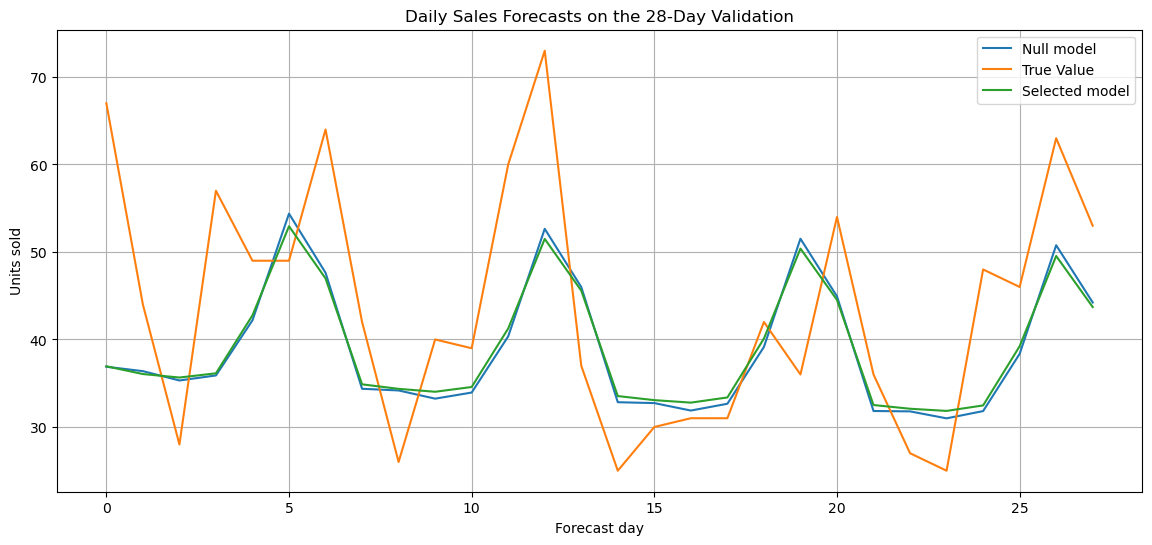

Active days per feature (28-day holdout)


Christmas                     0
Christmas__before             0
Christmas__after              0
Easter                        0
Easter__before                0
Easter__after                 0
Thanksgiving                  0
Thanksgiving__before          0
Thanksgiving__after           0
Christmas__before__ord2       0
Christmas__after__ord2        0
Easter__before__ord2          0
Easter__after__ord2           0
Thanksgiving__before__ord2    0
Thanksgiving__after__ord2     0
dtype: int64

In [78]:
# Final training of the model

# best_feature_block

final_features = []

if best_feature_block != 'null_model':
    source_set = best_feature_block.rsplit('__', 1)[0]
    selected_blocks = sarimax_features_to_test[best_feature_block]

    final_features = [
        feature for feature in feature_sets[source_set]
        if feature.split('__', 1)[0] in selected_blocks
    ]

if final_features:
    exog_train = df_training[final_features].reset_index(drop=True)
    exog_val = df_validation[final_features].reset_index(drop=True)
else:
    exog_train = None
    exog_val = None


model_sarimax = SARIMAX(
    endog=df_item_training.reset_index(drop=True),
    exog=exog_train,
    order=null_model_order,
    seasonal_order=null_model_seasonal_order,
    trend='n'    
)

with warnings.catch_warnings():
    warnings.simplefilter('ignore')    
    result = model_sarimax.fit(
        maxiter=1000 ,
        disp=False    
    )

converged = result.mle_retvals.get('converged', False)
if not converged: print('Selected Model Not converged')

model_sarimax_null = SARIMAX(
    endog=df_item_training.reset_index(drop=True),
    order=null_model_order,
    seasonal_order=null_model_seasonal_order,
    trend='n'    
)

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    result_null = model_sarimax_null.fit(
        maxiter=1000 ,
        disp=False    
    )
    
converged_null = result_null.mle_retvals.get('converged', False)
if not converged_null: print('Null Model Not converged')

forecast = result.get_forecast(
    steps=forecast_horizon,
    exog=exog_val
).predicted_mean


mse_val = mean_squared_error(forecast,df_item_validation)

forecast_null = result_null.get_forecast(
    steps=forecast_horizon
).predicted_mean


mse_val_null = mean_squared_error(forecast_null,df_item_validation)

naiv_pred = df_item_training.iloc[-7:]
naiv_pred = pd.concat(
    [
        naiv_pred,
        naiv_pred,
        naiv_pred,
        naiv_pred
    ]
)
naiv_pred

mse_naiv = mean_squared_error(naiv_pred,df_item_validation)

print(f'\n{"=" * 60}\nFINAL 28-DAY EVALUATION\n{"=" * 60}')
print(f'Selected model MSE:               {mse_val:.4f}')
print(f'Null model MSE:                   {mse_val_null:.4f}')
print(f'Naiv model MSE:                   {mse_naiv:.4f}\n')

print(f'MSE difference (selected - null): {(mse_val - mse_val_null):.4f}')
print(f'MSE difference (selected - naiv): {(mse_val - mse_naiv):.4f}\n')

print(f'Relative selected MSE change vs. null:     {(mse_val / mse_val_null - 1)*100:.4f}%')
print(f'Relative selected MSE change vs. naiv:     {(mse_val / mse_naiv - 1)*100:.4f}%')
print(f'Relative null MSE change vs. naiv:     {(mse_val_null / mse_naiv - 1)*100:.4f}%')


plt.figure(figsize=(14,6))
plt.plot(range(forecast_horizon),forecast_null,label='Null model')
plt.plot(range(forecast_horizon),df_item_validation,label='True Value')
plt.plot(range(forecast_horizon),forecast,label='Selected model')
plt.title('Daily Sales Forecasts on the 28-Day Validation')
plt.xlabel('Forecast day')
plt.ylabel('Units sold')
plt.legend()
plt.grid()
plt.show()

print('Active days per feature (28-day holdout)')
df_validation[final_features].ne(0).sum()


On the final 28-day holdout, SARIMAX had 42.62% lower MSE than the seasonal naive benchmark. The SARIMA null model had 42.47% lower MSE than the same benchmark.

SARIMAX achieved the lowest MSE (139.3543 versus 139.7080 for SARIMA). However, the improvement over the null model was only 0.25%. This small improvement is consistent with the t-test on the validation folds (Section 7.6.2), which did not show a statistically significant improvement from adding exogenous features.

All selected holiday features were zero throughout the holdout. Including them during training can still affect forecast accuracy during this period because accounting for past holiday effects can change the model’s estimated parameters.

## 9. Conclusion

This project developed a 28-day sales forecast for Walmart item `FOODS_1_018`, aggregating daily sales across four California stores. We used expanding-window validation to select a SARIMA(1,0,2)(0,1,1,7) baseline and evaluated calendar events, SNAP indicators, and monthly effects through Ridge-based feature screening followed by SARIMAX validation.

We selected the SARIMAX model with Christmas, Easter, and Thanksgiving features because it achieved the lowest mean validation MSE among models that converged on all 13 folds. It outperformed the SARIMA baseline in 10 of 13 folds, while its mean fold-level relative MSE change was slightly positive. The exploratory paired t-test did not show a statistically significant improvement from adding the holiday features (p = 0.1830).

On the final 28-day holdout, SARIMAX achieved the lowest MSE at 139.2832, an improvement of just 0.3% over the SARIMA null model (139.7080). Both models substantially outperformed the seasonal naive benchmark, with MSE improvements of 42.65% for SARIMAX and 42.47% for SARIMA.

All selected holiday features were zero throughout the holdout, so the final comparison reflects forecast performance outside the selected holiday windows. These findings apply to this single aggregated product series and the periods evaluated.